# 02 · Introdução à regressão polinomial

**Objetivo:** comparar os graus 1, 2, 3 e 5 em dados sintéticos com uma relação quadrática. O grau 1 representa a regressão linear; os demais incluem potências da variável de entrada.

Os modelos continuam lineares nos coeficientes. A expansão polinomial permite representar curvas em relação às variáveis originais.

Execute as células em ordem com o kernel **machine_learn**. Este exemplo inicial não depende de arquivos de dados externos.

## 1. Importações e caminhos

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Encontra o módulo e disponibiliza seu pacote Python, sem depender da pasta atual.
from pathlib import Path
PASTA_ATUAL = Path.cwd().resolve()
PASTA_PROJETO = next(
    (
        pasta
        for base in (PASTA_ATUAL, *PASTA_ATUAL.parents)
        for pasta in (
            base,
            base / "04_regressao_polinomial",
            base / "regressao_modelos_lineares" / "04_regressao_polinomial",
        )
        if (pasta / "src" / "polinomial" / "config.py").is_file()
    ),
    None,
)
if PASTA_PROJETO is None:
    raise FileNotFoundError("Não foi possível localizar o módulo 04_regressao_polinomial.")
PASTA_SRC = PASTA_PROJETO / "src"
if str(PASTA_SRC) not in sys.path:
    sys.path.insert(0, str(PASTA_SRC))

from polinomial.config import DADOS_EXEMPLO_SINTETICO
from polinomial.modelos import (
    RANDOM_STATE,
    construir_pipeline_polinomial,
    treinar_e_validar_modelo_polinomial,
)
from polinomial.graficos import plot_comparar_metricas_modelos
from polinomial.utils import organiza_resultados

sns.set_theme(palette="bright")

## 2. Dados de exemplo

Geramos os dados com semente fixa para reproduzir os resultados. A curva original é quadrática e recebe ruído aleatório. Mais adiante, esta etapa pode ser substituída pelo carregamento da base da aula.

In [2]:
rng = np.random.default_rng(RANDOM_STATE)
x = rng.uniform(-3, 3, size=150)
y = 3 + 2 * x + 0.8 * x**2 + rng.normal(0, 1.3, size=x.size)
df = pd.DataFrame({"x": x, "target": y})
X = df[["x"]]
y = df["target"]
df.head()

,x,target
0,1.643736,9.834742
1,-0.366729,2.578297
2,2.151588,10.800413
3,1.184208,5.143946
4,-2.434936,0.696171


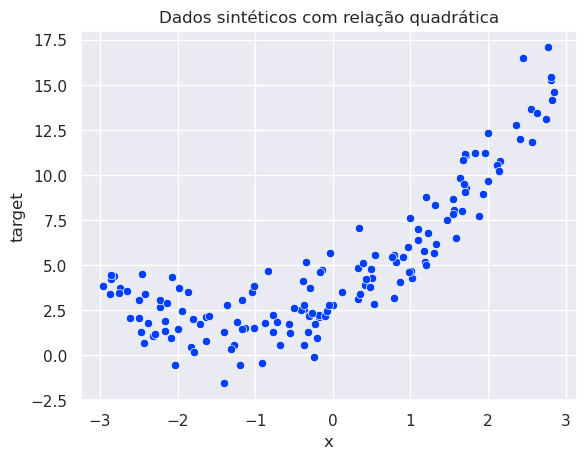

In [3]:
sns.scatterplot(data=df, x="x", y="target")
plt.title("Dados sintéticos com relação quadrática")
plt.show()

# Para salvar os dados localmente, descomente as próximas linhas.
# DADOS_EXEMPLO_SINTETICO.parent.mkdir(parents=True, exist_ok=True)
# df.to_csv(DADOS_EXEMPLO_SINTETICO, index=False)

## 3. Comparação com validação cruzada

Todos os graus usam as mesmas cinco divisões. PolynomialFeatures e StandardScaler ficam dentro do pipeline e são ajustados apenas no treino de cada divisão.

O scikit-learn armazena erros negativos nas métricas de scoring. A função `organiza_resultados` acrescenta MAE e RMSE positivos para facilitar a leitura.

In [4]:
GRAUS = [1, 2, 3, 5]
resultados = {
    f"Grau {grau}": treinar_e_validar_modelo_polinomial(X, y, grau=grau)
    for grau in GRAUS
}
df_resultados = organiza_resultados(resultados)
resumo = df_resultados.groupby("model").agg(
    R2_medio=("test_r2", "mean"),
    MAE_medio=("MAE", "mean"),
    RMSE_medio=("RMSE", "mean"),
    RMSE_desvio=("RMSE", "std"),
).sort_values("RMSE_medio")
resumo

,R2_medio,MAE_medio,RMSE_medio,RMSE_desvio
model,,,,
Grau 2,0.894277,1.023130,1.290687,0.097842
Grau 3,0.893949,1.020802,1.293552,0.094142
Grau 5,0.893424,1.031546,1.295908,0.115916
Grau 1,0.641223,1.976071,2.380452,0.170629


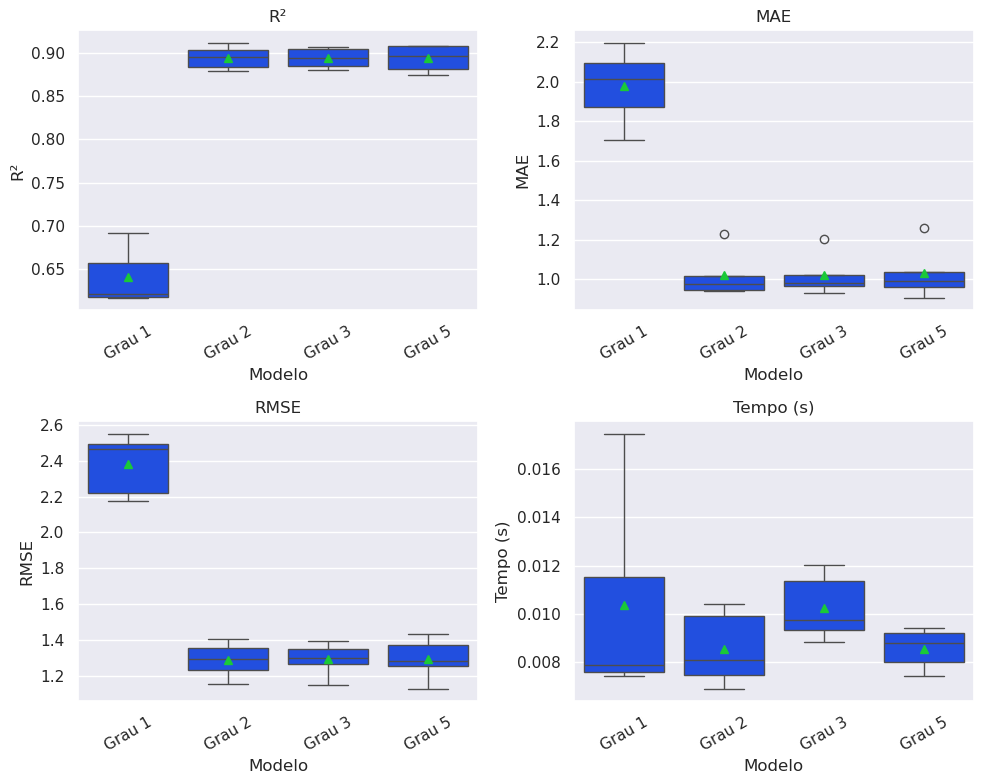

In [5]:
plot_comparar_metricas_modelos(df_resultados)

## 4. Visualização das curvas

Para ilustrar a forma das curvas, ajustamos cada grau em todos os dados. A avaliação de desempenho é a validação cruzada da seção anterior; este gráfico mostra os ajustes, sem constituir uma avaliação independente.

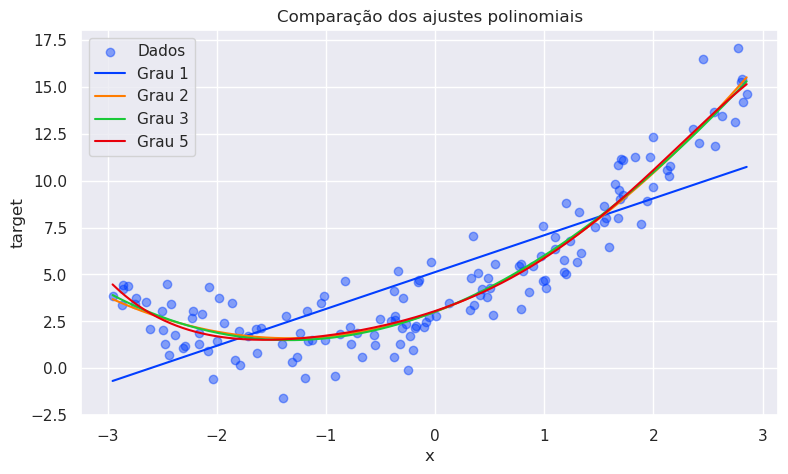

In [6]:
X_curva = pd.DataFrame({"x": np.linspace(X["x"].min(), X["x"].max(), 200)})
modelos_ajustados = {}
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(X["x"], y, alpha=0.45, label="Dados")
for grau in GRAUS:
    modelo = construir_pipeline_polinomial(grau=grau)
    modelo.fit(X, y)
    modelos_ajustados[grau] = modelo
    ax.plot(X_curva["x"], modelo.predict(X_curva), label=f"Grau {grau}")
ax.set(xlabel="x", ylabel="target", title="Comparação dos ajustes polinomiais")
ax.legend()
plt.show()

## 5. Interpretação e próximos passos

- R² maior indica melhor desempenho; MAE e RMSE menores indicam erros menores.
- Compare também a variação entre divisões, especialmente quando as médias forem próximas.
- Um grau mais alto aumenta a flexibilidade, mas não garante melhor generalização.
- Se escolher o grau com base nesses resultados, use uma avaliação independente ou validação aninhada para estimar o desempenho após a seleção.

**Próximos estudos:** curvas de aprendizado, maior variedade de graus e regularização com Ridge. A estrutura já permite passar um regressor diferente em `construir_pipeline_polinomial`.

[Voltar ao módulo](../README.md)